# Pneumonia Detection from Chest X-rays Using transfer learning (vgg16)
**Dataset:** Kaggle Chest X-ray Pneumonia  
**Task:** Binary classification (NORMAL vs PNEUMONIA)  
**Model:** Transfer Learning – VGG16  
**Metrics:** Accuracy, F1-score, Confusion Matrix  
**Explainability:** Grad-CAM visualization


In [ ]:
# 1 Install & Setup
!pip install -q opendatasets matplotlib seaborn


In [ ]:
!pip install -q opendatasets matplotlib seaborn

import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, EarlyStopping
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import Flatten, Dense, Dropout
from tensorflow.keras.models import Model
from sklearn.metrics import classification_report, confusion_matrix, f1_score


# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.19.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2) Download Dataset
We use the Kaggle Chest X-ray Pneumonia dataset.


In [ ]:
import opendatasets as od
od.download("https://www.kaggle.com/paultimothymooney/chest-xray-pneumonia")

train_dir = "chest-xray-pneumonia/chest_xray/train"
val_dir   = "chest-xray-pneumonia/chest_xray/val"
test_dir  = "chest-xray-pneumonia/chest_xray/test"


Skipping, found downloaded files in "./chest-xray-pneumonia" (use force=True to force download)


## 3) Image & Training Settings
We resize images to **150x150** and use grayscale input.  
Set batch size and epochs for training.


In [ ]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 25


## 4) Data Preprocessing and Augmentation
We normalize pixel values and apply augmentations to the training set.


In [ ]:
# Training augmentation and normalization
train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

# Validation & Test normalization
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

# Generators
train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',  # Binary labels
    seed=SEED
)

val_gen = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    seed=SEED
)

test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)


Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


## 5) Build vgg16 Model
We create a deep vgg16 with multiple convolutional blocks, batch normalization, dropout, and a binary classifier.


In [ ]:
# Load pretrained VGG16 convolutional base
IMAGE_SIZE = (224, 224)  # tuple instead of list
vgg = VGG16(input_shape=IMAGE_SIZE + (3,), weights='imagenet', include_top=False)

# Freeze pretrained layers
for layer in vgg.layers:
    layer.trainable = False

# Custom classifier
x = Flatten()(vgg.output)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
output = Dense(1, activation='sigmoid')(x)  # Binary output

model = Model(inputs=vgg.input, outputs=output)
model.compile(
    loss='binary_crossentropy',  # Binary loss
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,137,729 (80.63 MB)

 Trainable params: 6,423,041 (24.50 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

## 6) Callbacks
We use ModelCheckpoint, ReduceLROnPlateau, and EarlyStopping to optimize training.


In [ ]:
os.makedirs("models", exist_ok=True)
model_path = "models/finalvgg16.keras"

callbacks = [
    ModelCheckpoint(model_path, save_best_only=True, monitor='val_loss', verbose=1),
    ReduceLROnPlateau(monitor='val_accuracy', patience=2, factor=0.3, min_lr=1e-6, verbose=1),
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
]


## 7) Train Model
Training the vgg16 on the training set and validating on the validation set.


In [ ]:
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=callbacks
)


Epoch 1/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 676ms/step - accuracy: 0.8241 - loss: 0.7738
Epoch 1: val_loss improved from inf to 0.29177, saving model to models/finalvgg16.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 127s 731ms/step - accuracy: 0.8245 - loss: 0.7713 - val_accuracy: 0.8125 - val_loss: 0.2918 - learning_rate: 0.0010
Epoch 2/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 634ms/step - accuracy: 0.9366 - loss: 0.1630
Epoch 2: val_loss improved from 0.29177 to 0.27400, saving model to models/finalvgg16.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 104s 639ms/step - accuracy: 0.9367 - loss: 0.1630 - val_accuracy: 0.8750 - val_loss: 0.2740 - learning_rate: 0.0010
Epoch 3/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 629ms/step - accuracy: 0.9408 - loss: 0.1472
Epoch 3: val_loss did not improve from 0.27400
163/163 ━━━━━━━━━━━━━━━━━━━━ 103s 631ms/step - accuracy: 0.9409 - loss: 0.1471 - val_accuracy: 0.7500 - val_loss: 0.5924 - learning_rate: 0.0010
Epoch 4/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 632ms/step - accuracy: 0.9542 -

## 8) Evaluate Model
We evaluate on the test set and compute accuracy and F1-score.


In [ ]:

# 8 Evaluate Model
model = keras.models.load_model(model_path)

loss, acc = model.evaluate(test_gen)
print(f"Test Loss: {loss:.4f} | Test Accuracy: {acc*100:.2f}%")

y_pred_prob = model.predict(test_gen)
y_pred = (y_pred_prob > 0.5).astype(int).reshape(-1)
y_true = test_gen.classes

f1 = f1_score(y_true, y_pred)
print(f"F1-score: {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['NORMAL','PNEUMONIA']))


20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 297ms/step - accuracy: 0.9063 - loss: 0.3745
Test Loss: 0.2612 | Test Accuracy: 92.63%
20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 291ms/step
F1-score: 0.9424

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.94      0.86      0.90       234
   PNEUMONIA       0.92      0.96      0.94       390

    accuracy                           0.93       624
   macro avg       0.93      0.91      0.92       624
weighted avg       0.93      0.93      0.93       624



## 9) Confusion Matrix
Visualizing predictions with a heatmap.


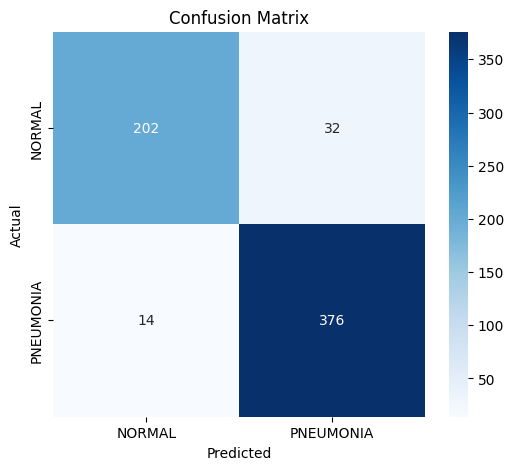

In [ ]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=['NORMAL','PNEUMONIA'],
            yticklabels=['NORMAL','PNEUMONIA'],
            cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


## 10) Training Curves
Plotting accuracy and loss curves over epochs.


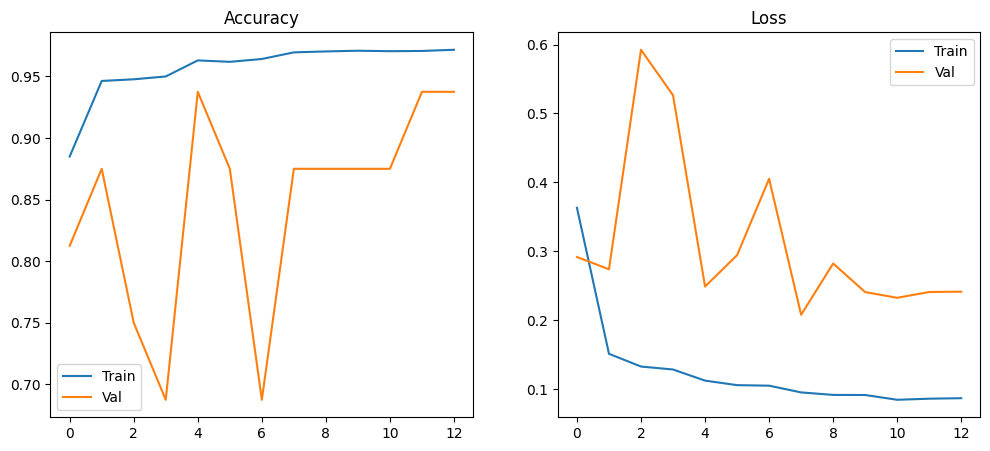

In [ ]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title("Loss")
plt.legend()

plt.show()


## References (VGG16)

1. Kaggle Chest X-ray Pneumonia Dataset: [https://www.kaggle.com/paultimothymooney/chest-xray-pneumonia](https://www.kaggle.com/paultimothymooney/chest-xray-pneumonia)
2. VGG16 Original Paper: [https://arxiv.org/abs/1409.1556](https://arxiv.org/abs/1409.1556)
3. Keras VGG16 Documentation: [https://keras.io/api/applications/vgg/](https://keras.io/api/applications/vgg/)
4. TensorFlow Documentation: [https://www.tensorflow.org](https://www.tensorflow.org)
5. Similar GitHub Project:  [https://github.com/swarnava-96/Pneumonia-Detection-using-VGG16/blob/main/Pneumonia_Detection.ipynb](https://github.com/swarnava-96/Pneumonia-Detection-using-VGG16/blob/main/Pneumonia_Detection.ipynb)
6. Pneumonia Detection Using Deep Learning (IRJET): [https://www.irjet.net/archives/V10/i11/IRJET-V10I1191.pdf](https://www.irjet.net/archives/V10/i11/IRJET-V10I1191.pdf)